In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

df = pd.read_csv('creditcard.csv')
y = df['Class']
X = df.drop(columns=['Class'])

In [2]:
# Сначала отделяем Test
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Затем Val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full
)

X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

print(f"Train: {X_train.shape}, фрод: {y_train.sum()}")
print(f"Val:   {X_val.shape}, фрод: {y_val.sum()}")
print(f"Test:  {X_test.shape}, фрод: {y_test.sum()}")

Train: (170883, 30), фрод: 295
Val:   (56962, 30), фрод: 99
Test:  (56962, 30), фрод: 98


In [3]:
scores = []

print("Обучение Random Forest (GridSearch)...")
for depth in [5, 10, 15]:
    for s in [1, 5, 10, 50]:
        for n in [50, 100, 150, 200]:
            rf = RandomForestClassifier(
                n_estimators=n,
                max_depth=depth,
                min_samples_leaf=s,
                class_weight='balanced',  
                random_state=42,
                n_jobs=-1                 
            )
            rf.fit(X_train, y_train)
            y_proba = rf.predict_proba(X_val)[:, 1]
            
            pr_auc = average_precision_score(y_val, y_proba)
            scores.append((depth, s, n, pr_auc))

# Создаем DataFrame и сортируем
columns = ['max_depth', 'min_samples_leaf', 'n_estimators', 'pr_auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores_sorted = df_scores.sort_values(by='pr_auc', ascending=False)

print("\nТоп-5 лучших комбинаций по PR-AUC:")
print(df_scores_sorted.head(5).to_string(index=False))

Обучение Random Forest (GridSearch)...

Топ-5 лучших комбинаций по PR-AUC:
 max_depth  min_samples_leaf  n_estimators   pr_auc
        15                 1           150 0.799683
        15                 1           100 0.799333
        15                 1           200 0.799278
        15                 1            50 0.787650
        15                 5           100 0.787600


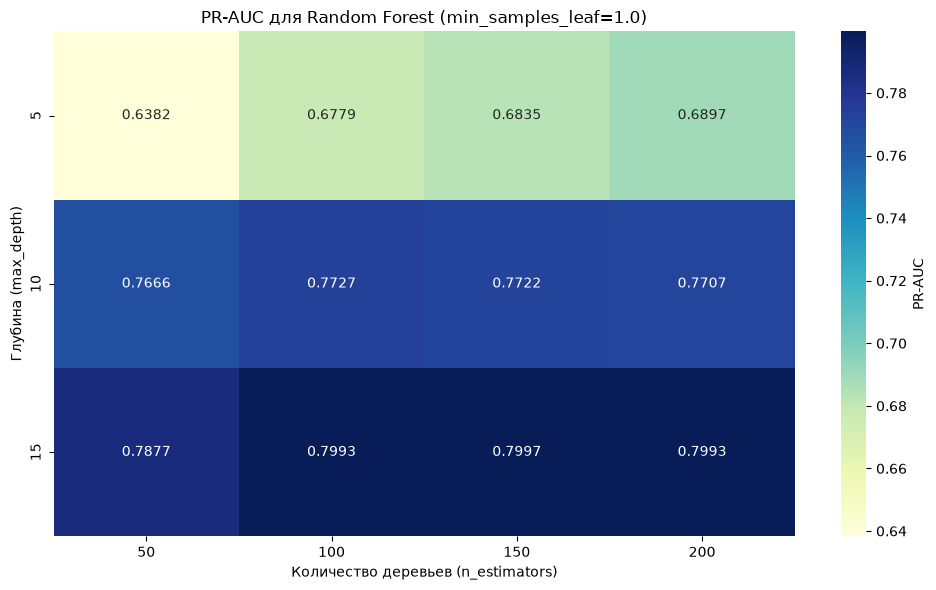

In [4]:
# Берем лучшее значение min_samples_leaf из Топ-1
best_s = df_scores_sorted.iloc[0]['min_samples_leaf'] 
df_filtered = df_scores[df_scores['min_samples_leaf'] == best_s]

df_pivot = df_filtered.pivot(
    index='max_depth', 
    columns='n_estimators', 
    values='pr_auc'
)

plt.figure(figsize=(10, 6))
sns.heatmap(df_pivot, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'PR-AUC'})
plt.title(f'PR-AUC для Random Forest (min_samples_leaf={best_s})')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('Глубина (max_depth)')
plt.tight_layout()
plt.show()

In [5]:
# Берем лучшие параметры
best_params = df_scores_sorted.iloc[0]
best_depth = int(best_params['max_depth'])
best_s = int(best_params['min_samples_leaf'])
best_n = int(best_params['n_estimators'])
print(f"Лучшие параметры: max_depth={best_depth}, min_samples_leaf={best_s}, n_estimators={best_n}")

# Обучаем на train
rf_val = RandomForestClassifier(
    n_estimators=best_n, max_depth=best_depth, min_samples_leaf=best_s,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_val.fit(X_train, y_train)
y_val_proba = rf_val.predict_proba(X_val)[:, 1]

# Подбор порога
print(f"\n{'Threshold':<12} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-" * 45)

best_threshold = 0
best_f1 = 0

for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    y_val_pred = (y_val_proba >= t).astype(int)
    p = precision_score(y_val, y_val_pred, zero_division=0)
    r = recall_score(y_val, y_val_pred, zero_division=0)
    f = f1_score(y_val, y_val_pred, zero_division=0)
    
    print(f"{t:<12.1f} {p:>10.4f} {r:>10.4f} {f:>10.4f}")
    
    if f > best_f1:
        best_f1 = f
        best_threshold = t

print(f"\nЛучший порог (по F1): {best_threshold} (F1 = {best_f1:.4f})")

Лучшие параметры: max_depth=15, min_samples_leaf=1, n_estimators=150

Threshold     Precision     Recall         F1
---------------------------------------------
0.1              0.3934     0.8384     0.5355
0.2              0.6752     0.7980     0.7315
0.3              0.7723     0.7879     0.7800
0.4              0.8556     0.7778     0.8148
0.5              0.8837     0.7677     0.8216
0.6              0.8889     0.7273     0.8000
0.7              0.8919     0.6667     0.7630
0.8              0.9375     0.6061     0.7362
0.9              0.9464     0.5354     0.6839

Лучший порог (по F1): 0.5 (F1 = 0.8216)


In [6]:
# Обучаем финальную модель
rf_final = RandomForestClassifier(
    n_estimators=best_n, max_depth=best_depth, min_samples_leaf=best_s,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_final.fit(X_train_full, y_train_full)

# Предсказания на тесте
y_test_proba_rf = rf_final.predict_proba(X_test)[:, 1]
y_test_pred_rf = (y_test_proba_rf >= best_threshold).astype(int)

print(f"=== RANDOM FOREST (FINAL, threshold={best_threshold}) ===")
print(f"PR AUC   : {average_precision_score(y_test, y_test_proba_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred_rf):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred_rf):.4f}")
print(f"F1       : {f1_score(y_test, y_test_pred_rf):.4f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_test_proba_rf):.4f}")

=== RANDOM FOREST (FINAL, threshold=0.5) ===
PR AUC   : 0.8543
Precision: 0.8020
Recall   : 0.8265
F1       : 0.8141
ROC AUC  : 0.9719
